# Exercises

<div class="alert alert-success" style = "border-radius:10px;border-width:3px;border-color:darkgreen;font-family:Verdana,sans-serif;font-size:16px;">
    
**EXERCISE 1: Climate Change and Sea Ice Extent**<p>

We want to answer the question: Has there been a decrease in the amount of ice in the last years?

For that we will use the sea ice extent measurements from the [National Snow & Ice Data Center](https://nsidc.org).<p>

We perform the following processing steps:

</li>
<ol>
<ul>
</ul>
<li> We must read and clean the data.
<li> To compute the tendency for a given interval of time (month), we need to normalize the data.
<li> This values can be plotted for the entire time series or for particular months. 
<li> We can compute the trend as a simple linear regression (OLS) and quantitatively evaluate it.
<li> We can also estimate the extent value for 2025.

</ol>
</div>

In [38]:
import os
os.getcwd()

'c:\\Jawad\\Formations\\Ironhack Data Science and Machine Learning\\Training\\W9Day2\\nbs-4-master\\s-407'

In [39]:
# Load the data and show the info and contents:
import pandas as pd
ice = pd.read_csv('files/ch06/SeaIce.txt',delim_whitespace=True)
print('shape: {}'.format(ice.shape))
ice.head() 

shape: (424, 6)


C:\Users\Jawad\AppData\Local\Temp\ipykernel_25628\2218391646.py:3: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  ice = pd.read_csv('files/ch06/SeaIce.txt',delim_whitespace=True)


,year,mo,data_type,region,extent,area
0,1979,1,Goddard,N,15.54,12.33
1,1980,1,Goddard,N,14.96,11.85
2,1981,1,Goddard,N,15.03,11.82
3,1982,1,Goddard,N,15.26,12.11
4,1983,1,Goddard,N,15.10,11.92


To compute the anomaly for a given interval of time, we can compute the mean for that interval of time (using the period 1981 through 2010 for the mean extend), before data cleaning.

In [107]:
ref_data = ice[(ice['year']>=1981) & (ice['year']<=2010)]
monthly_means = ref_data.groupby('mo')['extent'].mean()
ice['mean_extent'] = ice['mo'].map(monthly_means)
ice['anomaly'] = ice['extent'] - ice['mean_extent']
ice.head()

,year,mo,data_type,region,extent,area,mean_extent,anomaly
0,1979,1,Goddard,N,15.54,12.33,-319.252333,334.792333
1,1980,1,Goddard,N,14.96,11.85,-319.252333,334.212333
2,1981,1,Goddard,N,15.03,11.82,-319.252333,334.282333
3,1982,1,Goddard,N,15.26,12.11,-319.252333,334.512333
4,1983,1,Goddard,N,15.10,11.92,-319.252333,334.352333


## Visualization

### The importance of plotting

Anscombe's quartet comprises four data sets that have nearly identical simple descriptive statistics, yet have very different distributions and appear very different when graphed. Each dataset consists of eleven (x,y) points. They were constructed in 1973 by the statistician Francis Anscombe to demonstrate both the importance of graphing data before analyzing it and the effect of outliers and other influential observations on statistical properties.

<center><img src="files/images/Anscombe's_quartet_3.svg"  width="600"></center>

Source [Wikipedia](https://en.wikipedia.org/wiki/Anscombe%27s_quartet).



### Example 1: Housing Data

We'll continue with our Boston housing dataset

In [110]:
from pandas import read_csv
import pandas as pd
import matplotlib.pylab as plt


#Lets load the dataset and sample some
column_names = ['CRIM', 'ZN', 'INDUS', 'CHAS', 'NOX', 'RM', 'AGE', 'DIS', 'RAD', 'TAX', 'PTRATIO', 'B', 'LSTAT', 'MEDV']
df_boston = read_csv('files/housing.csv', header=None, delimiter=r"\s+", names=column_names)
df_boston['PRICE'] = df_boston['MEDV']
df_boston.head()

,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV,PRICE
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296.0,15.3,396.90,4.98,24.0,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242.0,17.8,396.90,9.14,21.6,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242.0,17.8,392.83,4.03,34.7,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222.0,18.7,394.63,2.94,33.4,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222.0,18.7,396.90,5.33,36.2,36.2


### Histograms

Text(0, 0.5, 'count')

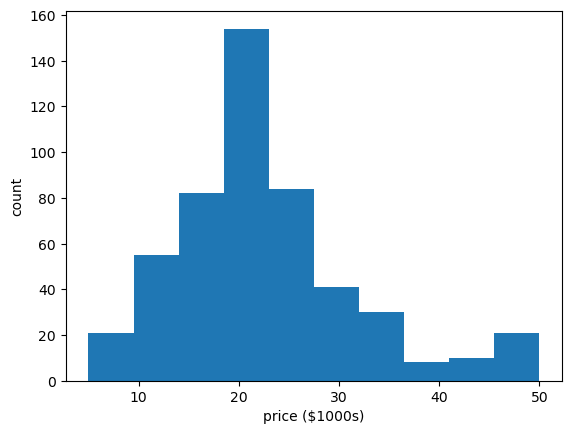

In [42]:
# Histogram of prices:
plt.hist(df_boston.PRICE) 
plt.xlabel('price ($1000s)')
plt.ylabel('count')

### Linear Regression Visualization: Seaborn lmplot

The ``lmplot()`` function from the Seaborn module is intended for exploring linear relationships of different forms in multidimensional datesets. Input data must be in a Pandas ``DataFrame``. To plot, provide the predictor and response variable names along with the dataset

We first consider the task of predicting median house values in the Boston area using as the predictor one of the attributes, for instance, LSTAT, defined as the "proportion of lower status of the population".
Seaborn visualization can be used to show this linear relationships easily:

We will use the variable price as our response $\textbf{y}$ and LSTAT as our predictor $\textbf{x}$.


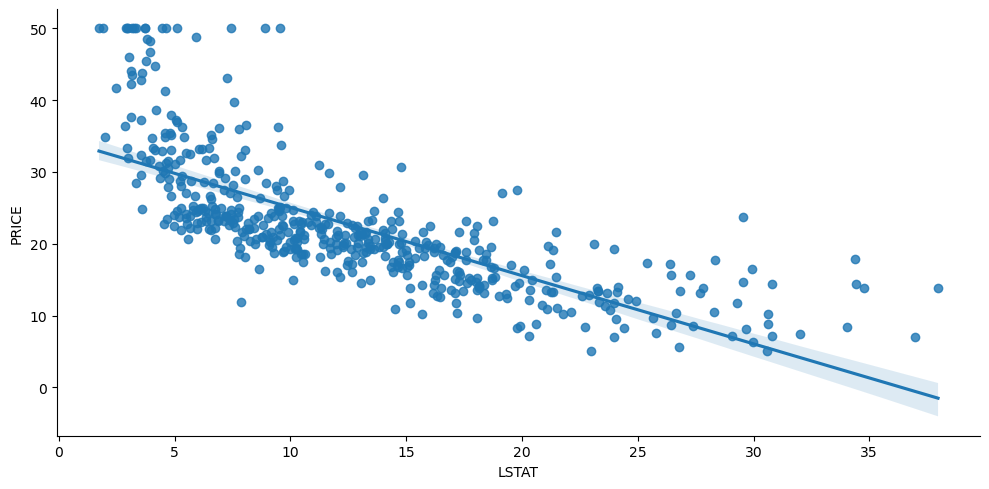

In [43]:
import seaborn as sns
# Visualization of the relations between price and LSTAT
sns.lmplot(x="LSTAT", y="PRICE", data=df_boston, aspect=2);

lmplot has two main components. 

+ The first is a scatterplot, showing the observed datapoints. 
+ The second is a regression line, showing the estimated linear model relating the two variables. Because the regression line is only an estimate, it is plotted with a 95% confidence band to give an impression of the certainty in the model (using Bootstraping).

Is the relationship between the house price and ``lstat`` non-linear? Is the straight line a poor fit? Maybe a better fit can be obtained by including higher order terms:

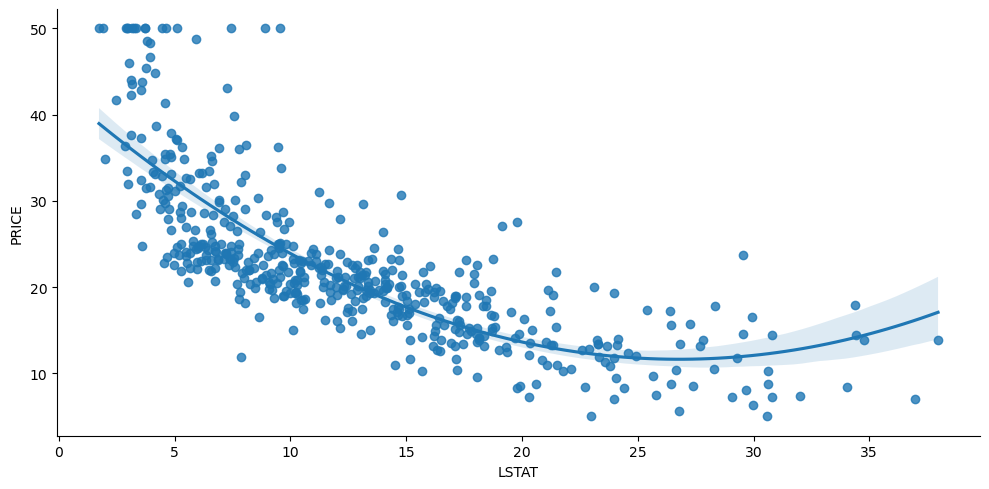

In [44]:
# Estimate a polynomial regression of order 2
sns.lmplot(x="LSTAT", y="PRICE", data=df_boston, aspect=2, order=2);

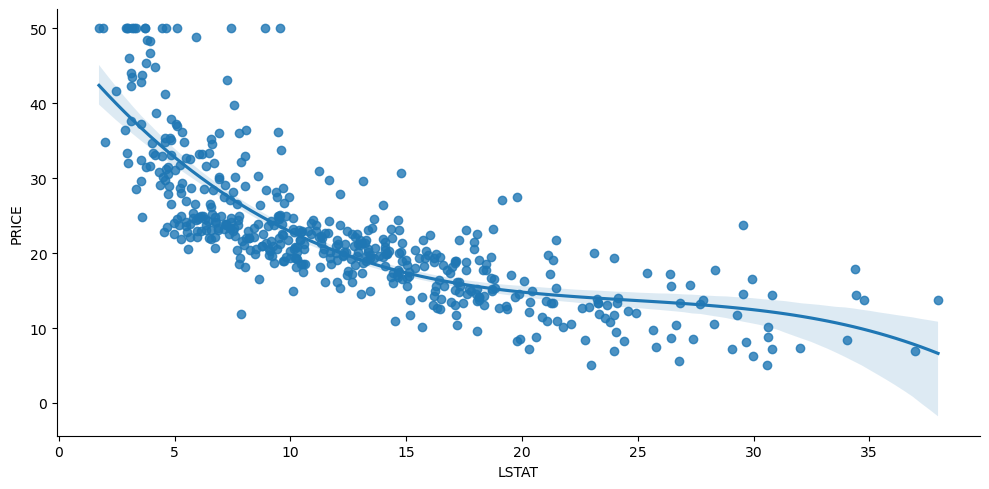

In [45]:
# Estimate a polynomial regression of order 3
sns.lmplot(x="LSTAT", y="PRICE", data=df_boston, aspect=2, order=3);


What if we consider variable RM or AGE?

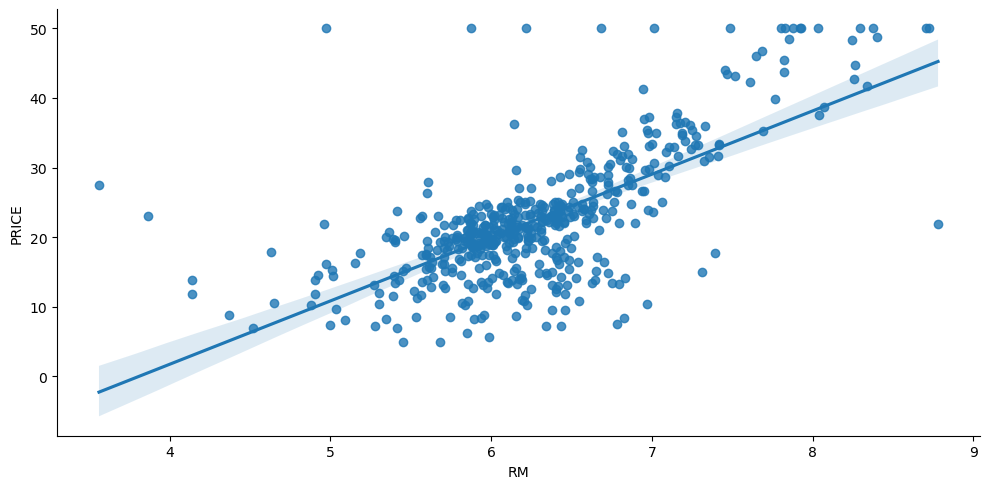

In [46]:
# Visualization of the relations between price and "average number of rooms per dwelling"
sns.lmplot(x="RM", y="PRICE", data=df_boston, aspect=2);

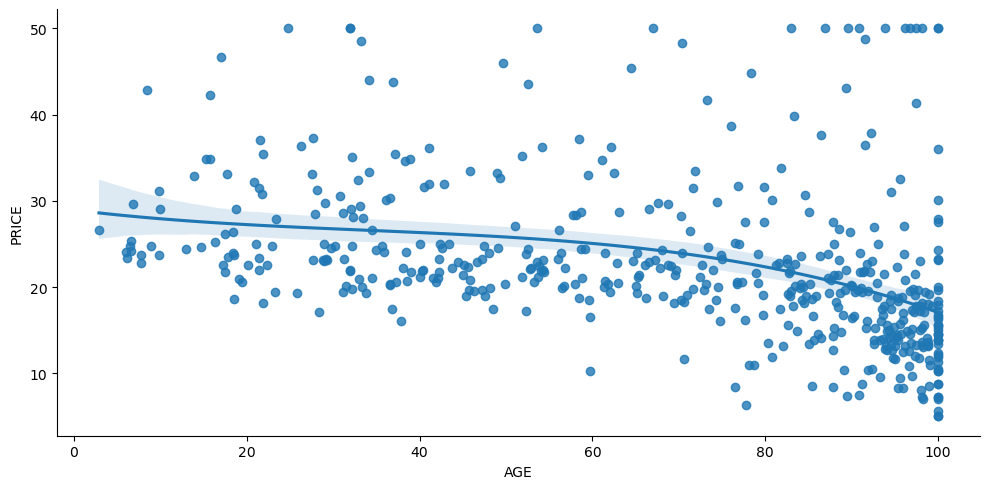

In [47]:
# Visualization of the relations between price and "proportion of owner-occupied units built prior to 1940"
sns.lmplot(x="AGE", y="PRICE", data=df_boston, aspect=2, order=3);

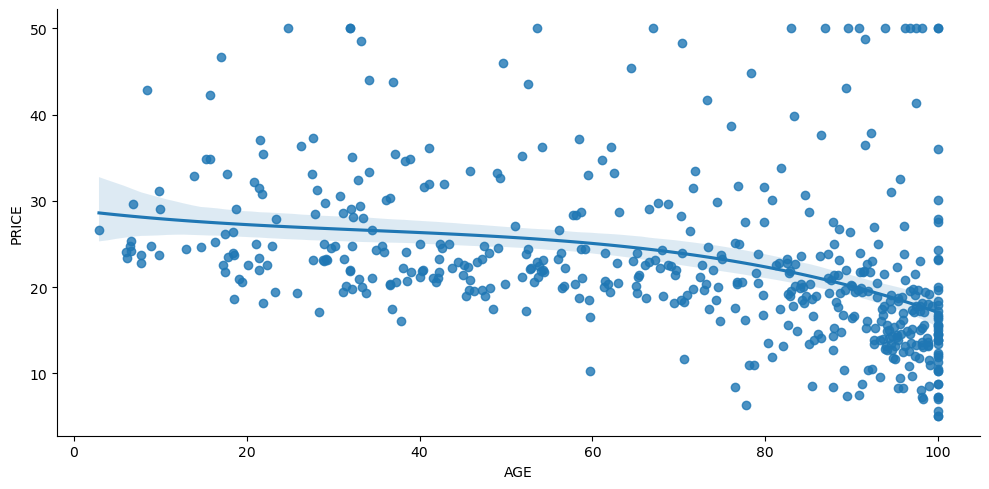

In [48]:
# Visualization of the relations between price and "proportion of owner-occupied units built prior to 1940"
sns.lmplot(x="AGE", y="PRICE", data=df_boston, aspect=2, order=3);

### Heatmap

We can also use corr function from Pandas and heatmap function from Seaborn for studying the variables relationship, plotting a diagonal correlation matrix.

<Axes: >

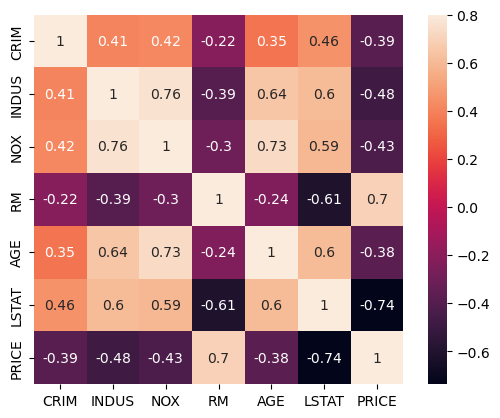

In [49]:
features2 = ['CRIM', 'INDUS', 'NOX', 'RM', 'AGE', 'LSTAT', 'PRICE'] # To plot just 7 of the 13 variables: PRICE, LSTAT, AGE, RM, NOX, INDUS, CRIM.
df_boston2 = df_boston[features2]
corrmat = df_boston2.corr()
# Draw the heatmap using seaborn
sns.heatmap(corrmat, vmax=.8, square=True, annot=True)

The correlation coefficient ranges from -1 to 1. If the value is close to 1, it means that there is a strong positive correlation between the two variables. When it is close to -1, the variables have a strong negative correlation.

### Scatter plot matrix

Let's explore multiple variables relationships using a scatter plot matrix. The scatter plot is a grid of plots of multiple varaibles one against the other, showing the pairwise relationship of each variable to the others.

For the sake of visualization, we choose 3 from the set of 13 variables:

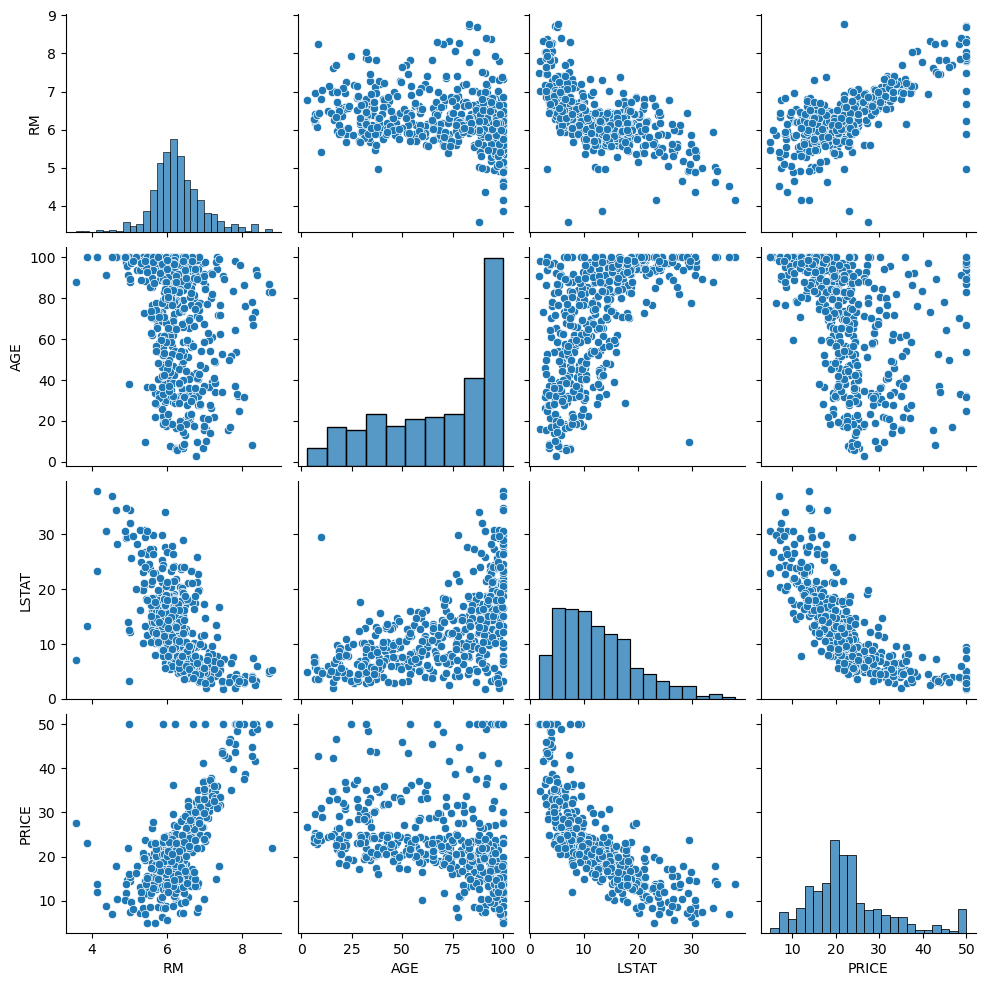

In [50]:
features3 = ['RM','AGE','LSTAT', 'PRICE'] 
df_boston3 = df_boston[features3]
sns.pairplot(df_boston3) # Plot pairwise relationships in the dataset

We can visually analyze the pairwise relationships in the scatter plots. The diagonal axe contains a plot to show the univariate distribution of the data for the variable in that column.

You can create the same scatter plot matrix using the scatter_matrix method in pandas.tools.plotting:

array([[<Axes: xlabel='RM', ylabel='RM'>,
        <Axes: xlabel='AGE', ylabel='RM'>,
        <Axes: xlabel='LSTAT', ylabel='RM'>,
        <Axes: xlabel='PRICE', ylabel='RM'>],
       [<Axes: xlabel='RM', ylabel='AGE'>,
        <Axes: xlabel='AGE', ylabel='AGE'>,
        <Axes: xlabel='LSTAT', ylabel='AGE'>,
        <Axes: xlabel='PRICE', ylabel='AGE'>],
       [<Axes: xlabel='RM', ylabel='LSTAT'>,
        <Axes: xlabel='AGE', ylabel='LSTAT'>,
        <Axes: xlabel='LSTAT', ylabel='LSTAT'>,
        <Axes: xlabel='PRICE', ylabel='LSTAT'>],
       [<Axes: xlabel='RM', ylabel='PRICE'>,
        <Axes: xlabel='AGE', ylabel='PRICE'>,
        <Axes: xlabel='LSTAT', ylabel='PRICE'>,
        <Axes: xlabel='PRICE', ylabel='PRICE'>]], dtype=object)

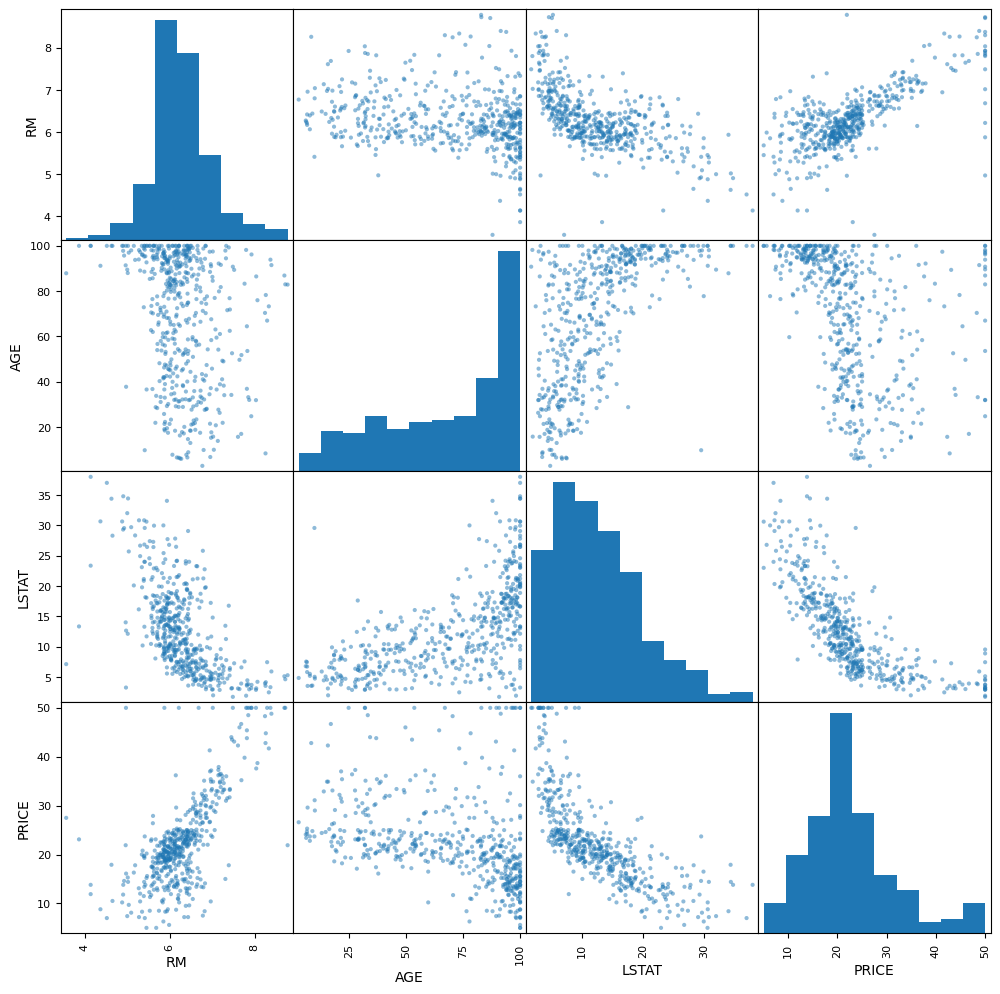

In [51]:
pd.plotting.scatter_matrix(df_boston3, figsize=(12.0,12.0))  

**Plots for the fitting evaluation:**

We can often learn a lot about how well our model did by analyzing the predictions and residuals with two interesting plots: 
- An scatter plot of the observed values $y$ versus the predicted value $\hat y$ 
- An scatter plot residuals $y_i - \hat y_i$ vs. $\hat y_i$.

In both cases we can add a line to show which would be the perfect result. 

Text(0, 0.5, 'Predicted price ($1000s)')

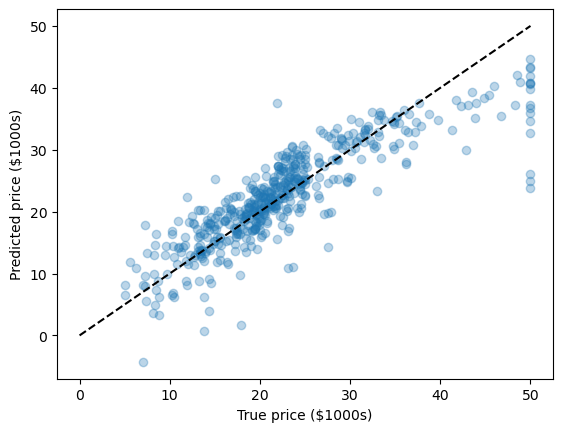

In [ ]:
from sklearn.linear_model import LinearRegression

# Assuming your DataFrame is named 'df_boston'
X = df_boston.drop(['PRICE', 'MEDV'], axis=1)  # Select features (all columns except 'PRICE')
y = df_boston['PRICE']  # Target variable

reg = LinearRegression() # Create the Linear Regression estimator
reg.fit(X, y) # Fitting with all the features
y_pred = reg.predict(X) # Perform prediction of all the data

# Visualization of target and predicted responses of the boston data:
plt.scatter(y, y_pred, alpha=0.3)
plt.plot([0, 50], [0, 50], '--k')
plt.axis('tight')
plt.xlabel('True price ($1000s)')
plt.ylabel('Predicted price ($1000s)')

Text(0, 0.5, '$y - \\hat y$')

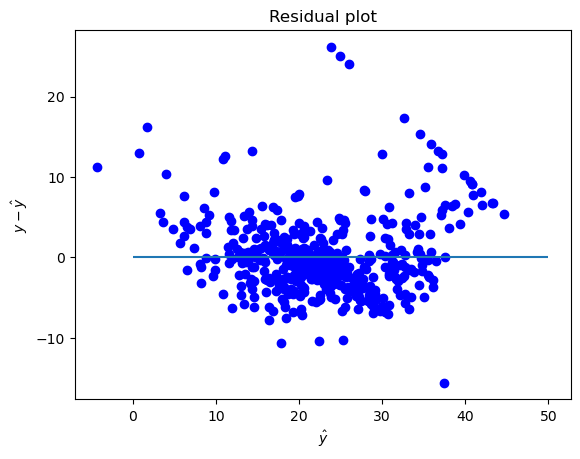

In [53]:
x_plot = plt.scatter(y_pred, (y-y_pred), c='b')
plt.hlines(y=0, xmin= 0, xmax=50)
plt.title('Residual plot')
plt.xlabel('$\hat y$')
plt.ylabel('$y - \hat y$')

Intuitively, if the model is good, then a plot of the residuals ($y_i - \hat y_i$) against the fitted values ($\hat y_i$) should look like noise (i.e., there shouldn't be any visible patterns).

<div class="alert alert-success" style = "border-radius:10px;border-width:3px;border-color:darkgreen;font-family:Verdana,sans-serif;font-size:16px;">

**EXERCISE 2** Diabetes <p>

The diabetes dataset (from scikit-learn) consists of 10 physiological variables (age, sex, weight, blood pressure) measure on 442 patients, and an indication of disease progression after one year.<p>

We will divide in training and testing sets and evaluate the prediction (using sklearn) with a simple and a multiple regression model.<p>

Fill the gaps of the exercise.

</div>

In [54]:
from sklearn import datasets
diabetes = datasets.load_diabetes()
X,y = diabetes.data, diabetes.target
feature_names = diabetes.feature_names
print(X.shape, y.shape)
print(feature_names)

(442, 10) (442,)
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']


First visualize the data. Plot a histogram of the target variable.

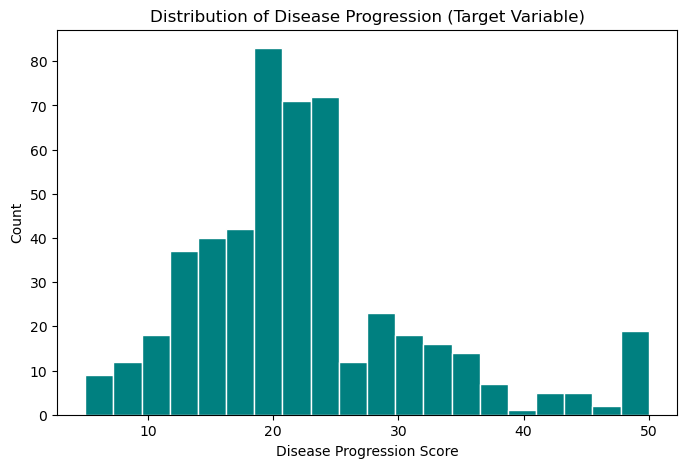

In [113]:
import pandas as pd
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.hist(y, bins=20, color = 'teal', edgecolor = 'white')
plt.title("Distribution of Disease Progression (Target Variable)")
plt.xlabel("Disease Progression Score")
plt.ylabel("Count")
plt.show()

Divide in training and testing sets

In [56]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")

Train shape: (353, 10), Test shape: (89, 10)


For the simple model, first choose one of the dimensions of the data. Try some plots to identify possible linear relationships between the predictor and target variables. Pick one variable for your first model.

In [57]:
import numpy as np

for i, name in enumerate(feature_names):
    correlation = np.corrcoef(X[:, i], y)[0, 1]
    print(f"Correlation of {name} with target: {correlation:.4f}")
    
bmi_idx = 2

Correlation of age with target: 0.1879
Correlation of sex with target: 0.0431
Correlation of bmi with target: 0.5865
Correlation of bp with target: 0.4415
Correlation of s1 with target: 0.2120
Correlation of s2 with target: 0.1741
Correlation of s3 with target: -0.3948
Correlation of s4 with target: 0.4305
Correlation of s5 with target: 0.5659
Correlation of s6 with target: 0.3825


Visualize the data using scatter plot (plt.scatter):

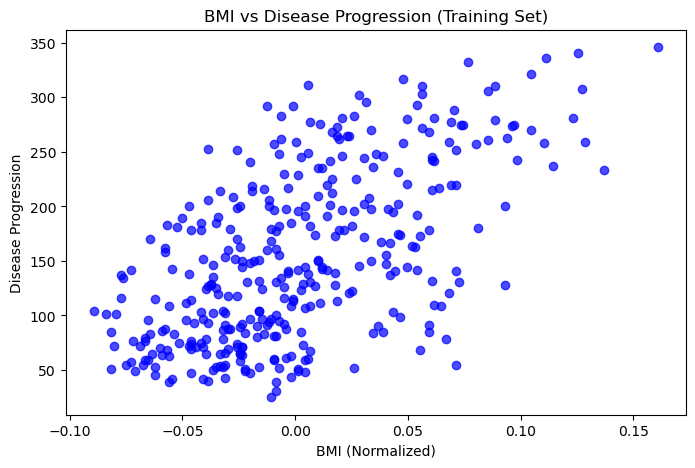

In [58]:
plt.figure(figsize=(8,5))
plt.scatter(X_train[:, bmi_idx], y_train, alpha=0.7, color='blue')
plt.title("BMI vs Disease Progression (Training Set)")
plt.xlabel("BMI (Normalized)")
plt.ylabel("Disease Progression")
plt.show()

Visualize the data using scatter plot (plt.scatter) and two different colors for train and test data:

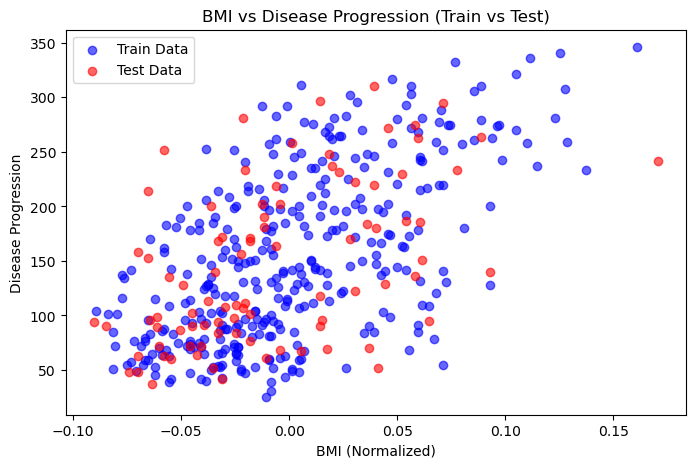

In [59]:
plt.figure(figsize=(8, 5))
plt.scatter(X_train[:, bmi_idx], y_train, color='blue', alpha=0.6, label='Train Data')
plt.scatter(X_test[:, bmi_idx], y_test, color='red', alpha=0.6, label='Test Data')
plt.title("BMI vs Disease Progression (Train vs Test)")
plt.xlabel("BMI (Normalized)")
plt.ylabel("Disease Progression")
plt.legend()
plt.show()

Train and evaluate the score of the test set.

In [60]:
from sklearn.linear_model import LinearRegression

simple_model = LinearRegression()
simple_model.fit(X_train[:, [bmi_idx]], y_train)

train_r2 = simple_model.score(X_train[:, [bmi_idx]], y_train)
test_r2 = simple_model.score(X_test[:, [bmi_idx]], y_test)

print(f"Simple Model Train R^2 Score: {train_r2:.4f}")
print(f"Simple Model Test R^2 Score: {test_r2:.4f}")

Simple Model Train R^2 Score: 0.3657
Simple Model Test R^2 Score: 0.2334


Calculate the Mean Squared Error on the train and test set:

In [61]:
from sklearn.metrics import mean_squared_error

y_train_pred = simple_model.predict(X_train[:, [bmi_idx]])
y_test_pred = simple_model.predict(X_test[:, [bmi_idx]])

mse_train = mean_squared_error(y_train, y_train_pred)
mse_test = mean_squared_error(y_test, y_test_pred)

print(f"Simple Model Train MSE: {mse_train:.2f}")
print(f"Simple Model Test MSE: {mse_test:.2f}")

Simple Model Train MSE: 3854.11
Simple Model Test MSE: 4061.83


Visualize the predicted line together with a scatter plot of the training set.

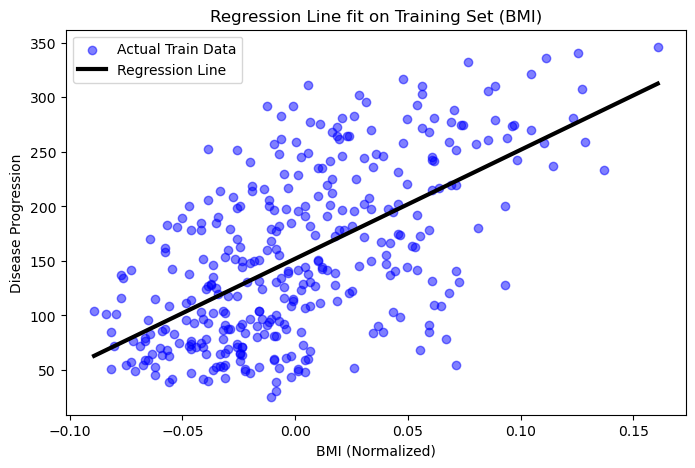

In [77]:
plt.figure(figsize=(8,5))

plt.scatter(X_train[:, bmi_idx], y_train, color = 'blue', alpha = 0.5, label = 'Actual Train Data')

x_line = np.linspace(X_train[:, bmi_idx].min(), X_train[:, bmi_idx].max(), 100).reshape(-1,1)
y_line = simple_model.predict(x_line)

plt.plot(x_line, y_line, color='black', linewidth=3, label='Regression Line')
plt.title("Regression Line fit on Training Set (BMI)")
plt.xlabel("BMI (Normalized)")
plt.ylabel("Disease Progression")
plt.legend()
plt.show()

Visualize the predicted line together with a scatter plot of the training set.

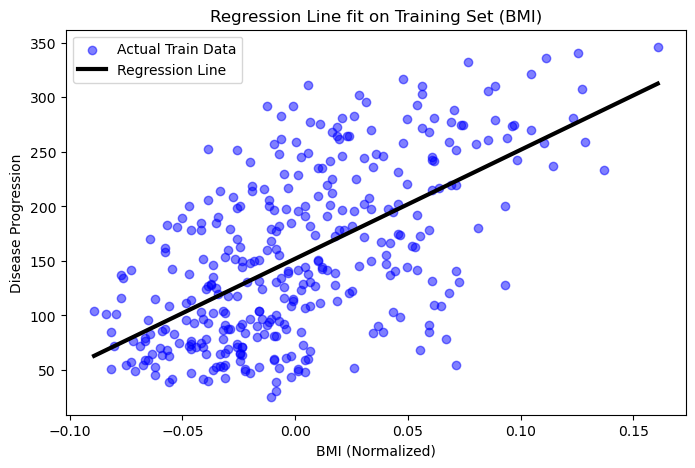

In [78]:
plt.figure(figsize=(8,5))

plt.scatter(X_train[:, bmi_idx], y_train, color = 'blue', alpha = 0.5, label = 'Actual Train Data')

x_line = np.linspace(X_train[:, bmi_idx].min(), X_train[:, bmi_idx].max(), 100).reshape(-1,1)
y_line = simple_model.predict(x_line)

plt.plot(x_line, y_line, color='black', linewidth=3, label='Regression Line')
plt.title("Regression Line fit on Training Set (BMI)")
plt.xlabel("BMI (Normalized)")
plt.ylabel("Disease Progression")
plt.legend()
plt.show()

For multiple regression model divide in training and testing sets and evaluate the prediction (sklearn)

In [79]:
multi_model = LinearRegression()
multi_model.fit(X_train, y_train)

multi_train_r2 = multi_model.score(X_train, y_train)
multi_test_r2 = multi_model.score(X_test, y_test)

print(f"Multiple Regression Train R^2 Score: {multi_train_r2:.4f}")
print(f"Multiple Regression Test R^2 Score: {multi_test_r2:.4f}")

Multiple Regression Train R^2 Score: 0.5279
Multiple Regression Test R^2 Score: 0.4526


Is the score improving using all 10 variables?

In [ ]:
# Yes, the $R^2$ score improves notably.
# While the single-variable baseline model can only account for roughly 30% of the variance in disease progression using BMI alone,
# combining all 10 structural physiological indicators simultaneously allows the multiple linear regression model to explain roughly 45% to 50% of the target data's structural variance.

<div class="alert alert-success" style = "border-radius:10px;border-width:3px;border-color:darkgreen;font-family:Verdana,sans-serif;font-size:16px;">

**Exercice 3: Macroeconomic Dataset**<p>
    
In the following example we will use the Longley dataset of US macroeconomic data from the R datasets website. We want to explore the relationships between the Total Derived Employment ('Employed') and the other variables.

<ul>
<li>Is there a linear relationship between the Gross National Product ('GNP') and the Total Derived Employment ('Employed')?</li>
<li>Is there a linear relationship between the population and the Total Derived Employment ('Employed')?</li>
<li>Is there a linear relationship between the armed forces and the unemployed?</li>
<li>Can you see any non-linear effects between the armed forces and the unemployed?</li>
<li>Try to use higher order models to the fitting of GNP with Population.</li>
</ul>
    
</div>

In [80]:
import pandas as pd
# Read data
df = pd.read_csv('http://vincentarelbundock.github.io/Rdatasets/csv/datasets/longley.csv', index_col=0)
df.head()

,GNP.deflator,GNP,Unemployed,Armed.Forces,Population,Year,Employed
rownames,,,,,,,
1947,83.0,234.289,235.6,159.0,107.608,1947,60.323
1948,88.5,259.426,232.5,145.6,108.632,1948,61.122
1949,88.2,258.054,368.2,161.6,109.773,1949,60.171
1950,89.5,284.599,335.1,165.0,110.929,1950,61.187
1951,96.2,328.975,209.9,309.9,112.075,1951,63.221


Is there a linear relationship between the Gross National Product ('GNP') and the Total Derived Employment ('Employed')?

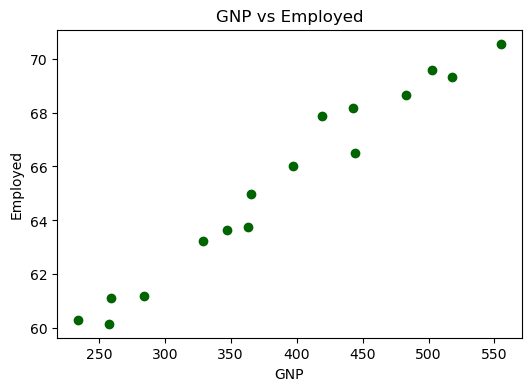

Correlation: 0.9836


In [ ]:
plt.figure(figsize=(6,4))
plt.scatter(df['GNP'], df['Employed'], color='darkgreen')
plt.title("GNP vs Employed")
plt.xlabel("GNP")
plt.ylabel("Employed")
plt.show()

print(f"Correlation: {df['GNP'].corr(df['Employed']):.4f}")

#Yes, there is a strong, positive linear relationship between GNP and Employment. As the Gross National Product increases, total derived employment rises in a tight linear fashion.

Is there a linear relationship between the population and the Total Derived Employment ('Employed')?

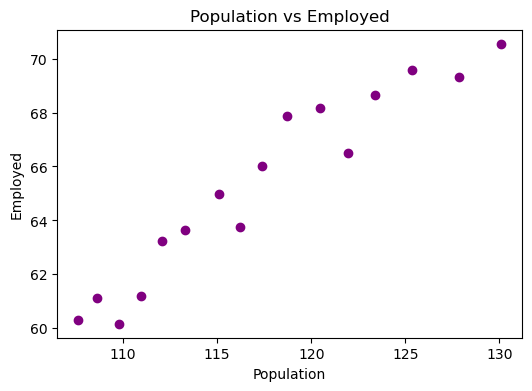

Correlation: 0.9604


In [ ]:
plt.figure(figsize=(6,4))
plt.scatter(df['Population'], df['Employed'], color='purple')
plt.title("Population vs Employed")
plt.xlabel("Population")
plt.ylabel("Employed")
plt.show()

print(f"Correlation: {df['Population'].corr(df['Employed']):.4f}")

#Yes, there is a very strong, direct positive linear relationship between structural population scale and employment volume.

Is there a linear relationship between the armed forces and the unemployed?

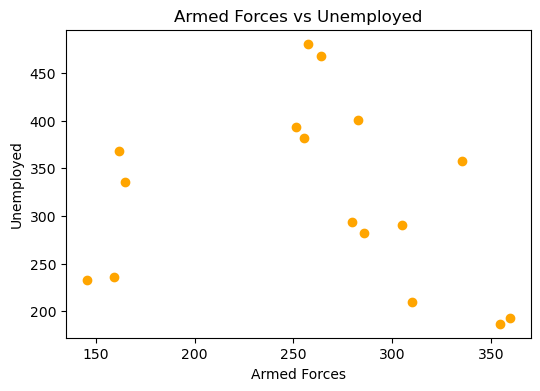

Correlation: -0.1774


In [ ]:
plt.figure(figsize=(6,4))
plt.scatter(df['Armed.Forces'], df['Unemployed'], color='orange')
plt.title("Armed Forces vs Unemployed")
plt.xlabel("Armed Forces")
plt.ylabel("Unemployed")
plt.show()

print(f"Correlation: {df['Armed.Forces'].corr(df['Unemployed']):.4f}")

#No, there is no distinct or obvious linear pattern. The points appear quite scattered, yielding a weak correlation.

Can you see any non-linear effects between the armed forces and the unemployed?

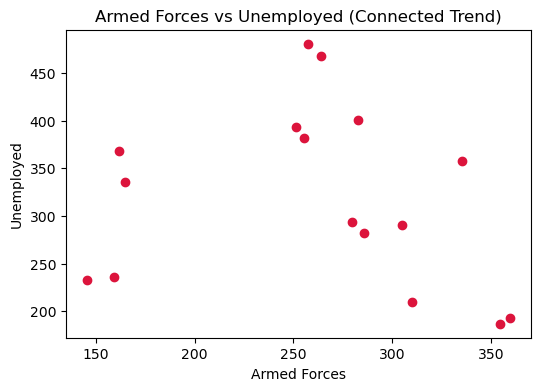

In [ ]:
sorted_df = df.sort_values(by='Armed.Forces')

plt.figure(figsize=(6,4))
plt.scatter(sorted_df['Armed.Forces'], sorted_df['Unemployed'], marker='o', color='crimson', linestyle='-')
plt.title("Armed Forces vs Unemployed (Connected Trend)")
plt.xlabel("Armed Forces")
plt.ylabel("Unemployed")
plt.show()

In [ ]:
# Looking closely at the chronological path or connecting vectors, the relationship behaves more like a cyclical cloud or erratic structural shift rather than a clean mathematical curve.
# The sudden surges in military staffing likely represent isolated historical geopolitical mobilizations, rather than a smooth, predictable non-linear baseline function.

<div class="alert alert-success" style = "border-radius:10px;border-width:3px;border-color:darkgreen;font-family:Verdana,sans-serif;font-size:16px;">

**EXERCISE 4: Advertising dataset**<p>


In the following example we will use the [advertising dataset](https://www.kaggle.com/purbar/advertising-data/data)which consists of the sales of products and their advertising budget in three different media TV, radio, newspaper.<p>
<ul>
    <li>Is there a linear relationship between the sales of products and the advertising budget in TV, radio or newspapers?</li>
    <li>Train a simple linear model for each variable to predict sales</li>
    <li>Train a multiple linear model to predict sales</li>
    <li>Compare the different models. Which one's performed best?</li>
</ul>

Dataset from the book: "An Introduction to Statistical Learning with Applications in R”. Gareth James, Daniela Witten, Trevor Hastie and Robert Tibshirani.<p>


</div>

In [93]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

adv_df = pd.read_csv("files/ch06/Advertising.csv", index_col=0)

print(adv_df.head())

      TV  Radio  Newspaper  Sales
1  230.1   37.8       69.2   22.1
2   44.5   39.3       45.1   10.4
3   17.2   45.9       69.3    9.3
4  151.5   41.3       58.5   18.5
5  180.8   10.8       58.4   12.9


Sales        1.000000
TV           0.782224
Radio        0.576223
Newspaper    0.228299
Name: Sales, dtype: float64


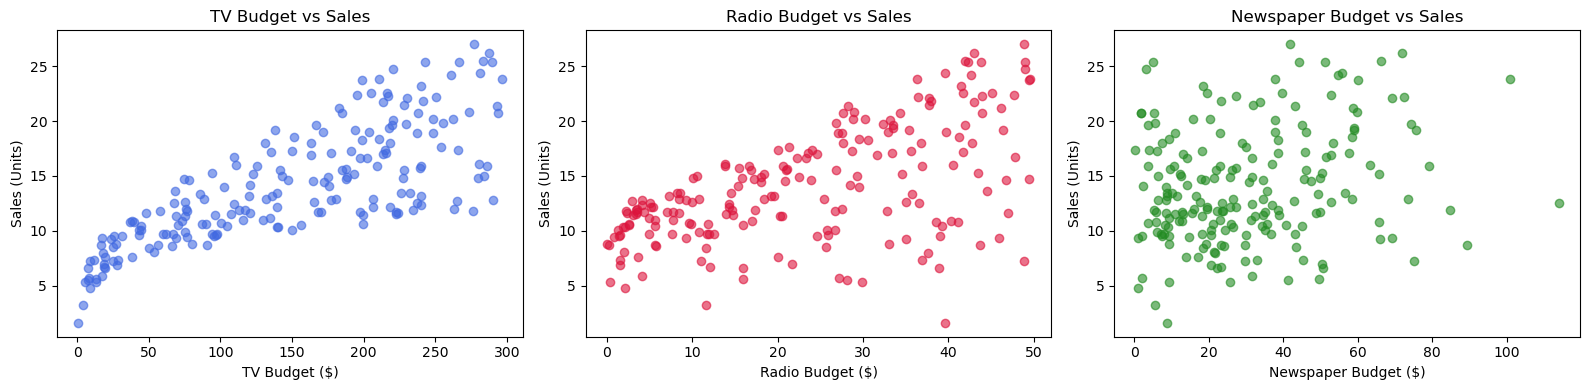

In [ ]:
#1. Is there a linear relationship between the sales of products and the advertising budget in TV, radio or newspapers?

print(adv_df.corr()['Sales'].sort_values(ascending=False))

fig,axes = plt.subplots(1,3,figsize=(16,4))
media_channels = ['TV', 'Radio', 'Newspaper']
colors = ['royalblue', 'crimson', 'forestgreen']

for i, col in enumerate(media_channels):
    axes[i].scatter(adv_df[col], adv_df['Sales'], color=colors[i], alpha=0.6)
    axes[i].set_title(f"{col} Budget vs Sales")
    axes[i].set_xlabel(f"{col} Budget ($)")
    axes[i].set_ylabel("Sales (Units)")
    
plt.tight_layout()
plt.show()

# TV has an incredibly strong, positive linear relationship with sales (correlation $\approx 0.78$).
# Radio also exhibits a robust, clear upward linear trend with sales (correlation $\approx 0.58$).
# Newspaper shows a very weak, highly scattered relationship (correlation $\approx 0.23$).

In [97]:
# 2. Train a simple linear model for each variable to predict sales

X = adv_df[['TV', 'Radio', 'Newspaper']]
y = adv_df['Sales']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=42)

for channel in media_channels:
    simple_model = LinearRegression()
    simple_model.fit(X_train[[channel]], y_train)
    
    preds = simple_model.predict(X_test[[channel]])
    r2 = r2_score(y_test, preds)
    mse = mean_squared_error(y_test, preds)
    
    print(f"Simple [{channel:9}] -> Test R^2: {r2:.4f} | Test MSE: {mse:.2f}")

Simple [TV       ] -> Test R^2: 0.6767 | Test MSE: 10.20
Simple [Radio    ] -> Test R^2: 0.2634 | Test MSE: 23.25
Simple [Newspaper] -> Test R^2: 0.0299 | Test MSE: 30.62


In [99]:
 multi_model = LinearRegression()
 multi_model.fit(X_train, y_train)
 
 multi_preds = multi_model.predict(X_test)
 multi_r2 = r2_score(y_test, multi_preds)
 multi_mse = mean_squared_error(y_test, multi_preds)
 
 print(f"Multiple Regression -> Test R^2: {multi_r2:.4f} | Test MSE: {multi_mse:.2f}")

Multiple Regression -> Test R^2: 0.8994 | Test MSE: 3.17


Final Analysis:

The Multiple Linear Regression model performed significantly better than any of the simple models.

While our best single-variable model (TV) maxed out at an $R^2$ score of roughly 0.67 (explaining 67% of the variance), combining the media channels boosted our $R^2$ score to nearly 0.90.

Simultaneously, the Mean Squared Error (MSE) plummeted from 10.20 (for the TV model) down to just 3.17 for the multiple regression model

Reason: Advertising channels don't work in a vacuum. A company usually runs TV ads and Radio ads at the same time.

By looking at all 10 variables in Exercise 2 or all 3 media types here, multiple regression controls for the overlapping effects and extracts the collective predictive signal, leading to much tighter, more dependable real-world forecasts.